# Risk Parity

## Project Statement

On December 13, 2019 the RPAR Risk Parity ETF listed, the first fund to sell "balanced risk across asset classes" to anyone with a brokerage account. Three months later it met the March 2020 volatility shock. On January 4, 2022 its levered sibling UPAR listed, at the start of the deepest drawdown in RPAR's record. On March 6, 2025 Bridgewater, whose All Weather fund originated the idea in 1996, listed its own ETF, ALLW. The file also holds NTSX, a levered 90/60 stock-bond fund, DBMF, a managed-futures fund, and the asset-class ETFs from which every one of these can be rebuilt back to 2008.

You are an allocator at the October 23, 2026 close choosing among these products and a construction of your own. Measure what each product is, decompose what it holds, build the strategy over a longer history than any live fund has, test what broke it in 2020 and 2022, and recommend.


## Context

| Fund | First trading day | Strategy | Annual expense |
|---|---|---|---:|
| RPAR Risk Parity ETF | 2019-12-13 | Four asset classes, each at 25% of target risk | 0.52% |
| UPAR Ultra Risk Parity ETF | 2022-01-04 | 1.4 times the RPAR Index's exposures | 0.68% |
| SPDR Bridgewater All Weather ETF (`ALLW`) | 2025-03-06 | Active allocation across stocks, nominal bonds, inflation-linked bonds, and commodities | 0.85% |
| WisdomTree U.S. Efficient Core Fund (`NTSX`) | 2018-08-02 | About 90% U.S. equities and 60% Treasury-futures notional | 0.20% |
| iMGP DBi Managed Futures Strategy ETF (`DBMF`) | 2019-05-08 | Long and short futures positions, rebalanced weekly | 0.85% |

Additional exposure details:

- **RPAR:** the index allocation is 35% TIPS, 25% global equities, 25% commodities, and 15% Treasuries implemented with bills collateralizing Treasury futures.
- **UPAR:** total exposure is 160% to 180% of net asset value.
- **ALLW:** derivative notional may exceed NAV; reported notional was 187% on October 23, 2026. Bridgewater's All Weather strategy dates to 1996.
- **NTSX:** the Treasury sleeve targets 3- to 8-year duration.
- **DBMF:** estimates the positioning of the 20 leading managed-futures funds in the SG CTA Index.

Use two daily-rebalanced benchmarks: **60/40**, with 60% `SPY` and 40% `IEF`; and a **four-asset portfolio**, with 25% each in `SPY`, `TLT`, `GLD`, and `DBC` (the *static four-way* in the calculations below).

Fund facts: issuer pages and prospectuses, October 26, 2026. Fund returns are net of fees. The file begins on each fund's first trading day; inception dates may be one day earlier.


## Data

| File | Sheets | Frequency | Sample |
|---|---|---|---|
| `data/project_risk_parity_20261023.xlsx` | `descriptions`, `total return index`, `daily returns`, `monthly returns`, `yields`, `data source` | daily; monthly from month-end levels, full months only | daily 2002-07-26 to 2026-10-23; monthly 2002-08 to 2026-09; yields to 2026-07-31 |

The return sheets contain simple total returns for the five funds and the asset-class ETFs `SPY`, `TLT`, `IEF`, `TIP`, `GLD`, `DBC`, `AGG`, and the cash funds `SHV` and `BIL`, derived from gross-dividend total-return indexes. A series is blank before the fund existed. `RPARTR` (RPAR's benchmark, a price index), `RSSB`, `RSST` and `PRPFX` are in the file for reference; no question uses them. The `yields` sheet holds 2-, 10- and 30-year zero-coupon Treasury yields in percent (Federal Reserve Board, Gurkaynak-Sack-Wright).

#### Notes

- Returns are daily, close to close, simple total returns on `SPY`'s calendar. Annualize with 252 days or 12 months: a mean by the count, a volatility by its square root.
- Cash is `SHV`; an excess return subtracts `SHV`'s return over the same period. Sharpe ratios use excess returns; drawdowns, skewness, VaR and CVaR use total returns.
- A portfolio levered $L$ times borrows at `SHV`: $r^{L}_t = r^f_t + L\,(r_t - r^f_t)$. Ignore transaction costs and financing spreads until Section 7 declares them.
- A wealth index for a drawdown equals 1 at the close before the window's first return, so a loss on the first day counts.
- VaR and CVaR are returns at the 5% level over one day unless a question says otherwise. A forecast for day $t$ uses data through $t-1$.
- Historical-simulation forecasts begin after a 252-day burn-in. EWMA uses a zero mean, seeds $\sigma^2$ with the variance of the first 21 returns, and forecasts from the 22nd day.
- A weight or signal set at the close of month $t-1$ acts in month $t$.
- One-way turnover at a rebalance is half the sum of absolute position changes, with positions as fractions of net asset value, so including leverage.


## Data Preview


In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('project_risk_parity_20261023.xlsx')
descriptions = pd.read_excel(DATA, sheet_name='descriptions').set_index('ticker')
levels = pd.read_excel(DATA, sheet_name='total return index', index_col='Date', parse_dates=True)
returns = pd.read_excel(DATA, sheet_name='daily returns', index_col='Date', parse_dates=True)
monthly = pd.read_excel(DATA, sheet_name='monthly returns', index_col='Date', parse_dates=True)
yields = pd.read_excel(DATA, sheet_name='yields', index_col='Date', parse_dates=True)

print(f'{returns.shape[1]} series, {returns.index[0].date()} to {returns.index[-1].date()}; yields to {yields.index[-1].date()}')
preview_funds = ['RPAR', 'UPAR', 'ALLW', 'NTSX', 'DBMF']
coverage = pd.DataFrame({
    'First return': returns[preview_funds].apply(pd.Series.first_valid_index).dt.strftime('%Y-%m-%d'),
    'Last return': returns[preview_funds].apply(pd.Series.last_valid_index).dt.strftime('%Y-%m-%d'),
    'Daily observations': returns[preview_funds].count(),
})
coverage.index.name = 'Fund'
display(coverage.style.format({'Daily observations': '{:,.0f}'}, na_rep='—').set_caption('Available daily fund returns'))


18 series, 2002-07-29 to 2026-10-23; yields to 2026-07-31


,First return,Last return,Daily observations
Fund,,,
RPAR,2019-12-16,2026-10-23,"1,723"
UPAR,2022-01-05,2026-10-23,"1,205"
ALLW,2025-03-07,2026-10-23,411
NTSX,2018-08-03,2026-10-23,"2,053"
DBMF,2019-05-09,2026-10-23,"1,876"


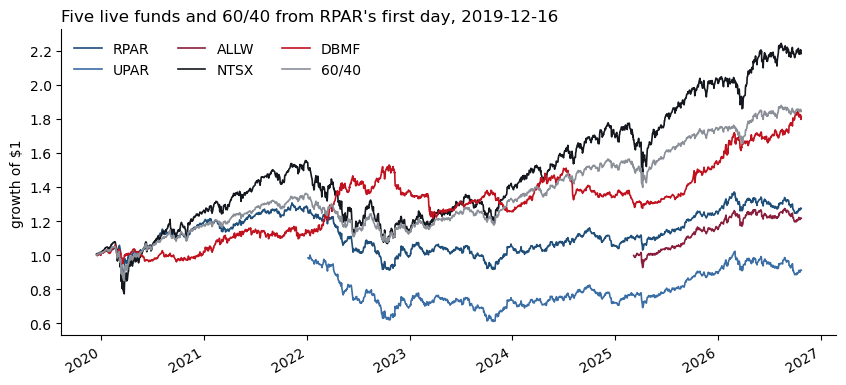

In [11]:
LIVE = ['RPAR', 'UPAR', 'ALLW', 'NTSX', 'DBMF']
returns['60/40'] = 0.6 * returns['SPY'] + 0.4 * returns['IEF']
returns['static four-way'] = 0.25 * (returns['SPY'] + returns['TLT'] + returns['GLD'] + returns['DBC'])

fig, ax = plt.subplots(figsize=(10, 4.5))
growth = (1 + returns.loc['2019-12-16':, LIVE + ['60/40']]).cumprod()
growth.plot(ax=ax, color=['#1f4e79', '#3b6ea5', '#8a1f3d', '#14181e', '#c1121f', '#8a8f98'], lw=1.2)
ax.set_ylabel('growth of $1'); ax.set_xlabel('')
ax.set_title('Five live funds and 60/40 from RPAR\'s first day, 2019-12-16', loc='left')
ax.legend(frameon=False, ncol=3); ax.spines[['top', 'right']].set_visible(False)
plt.show()


***


# 1. The Products


## 1.1

For `RPAR`, `UPAR`, `ALLW`, `NTSX`, `DBMF`, 60/40 and the static four-way, report over 2019-12-16 to 2026-10-23 and over 2022-01-05 to 2026-10-23:

* annualized mean and volatility, Sharpe ratio, skewness
* empirical 5% VaR and CVaR of daily returns
* maximum drawdown with its peak, trough and recovery dates
* calendar-year total returns for 2020 through 2026 to date, adding `SPY`, `TLT`, `TIP`, `GLD` and `DBC`

A fund that launched after a window opens starts later; mark it in the table.


In [12]:
def product_stats(returns, rf):
    returns = returns.dropna()
    excess_return = returns - rf.reindex(returns.index)
    sharpe = (excess_return.mean() / excess_return.std()) * np.sqrt(252)
    skewness = returns.skew()
    VaR_5 = np.percentile(returns, 5)
    CVaR_5 = returns[returns <= VaR_5].mean()
    wealth = (1 + returns).cumprod()
    wealth = pd.concat([pd.Series([1.0], index=[returns.index[0] - pd.Timedelta(days=1)]), wealth])
    drawdown = wealth / wealth.cummax() - 1
    trough = drawdown.idxmin()
    peak = wealth[:trough].idxmax()
    recovery = wealth[trough:][wealth[trough:] >= wealth[peak]]
    return pd.Series({
        "Start": returns.index[0].date(),
        "Annualized Mean": returns.mean() * 252,
        "Annualized Volatility": returns.std() * np.sqrt(252),
        "Sharpe Ratio": sharpe,
        "Skewness": skewness,
        "Empirical 5% VaR": VaR_5,
        "Empirical 5% CVaR": CVaR_5,
        "Max Drawdown": drawdown.min(),
        "Peak": peak.date(),
        "Trough": trough.date(),
        "Recovery": recovery.index[0].date() if len(recovery) else None
    })
products = LIVE + ['60/40', 'static four-way']
start_2019 = pd.DataFrame({p: product_stats(returns.loc['2019-12-16':'2026-10-23', p], returns['SHV'])
              for p in products}).T
start_2022 = pd.DataFrame({p: product_stats(returns.loc['2022-01-05':'2026-10-23', p], returns['SHV'])
              for p in products}).T

late_2019 = pd.to_datetime(start_2019['Start']) > pd.Timestamp('2019-12-16')
start_2019.index = [f"{p} (from {s})" if l else p
               for p, s, l in zip(start_2019.index, start_2019['Start'], late_2019)]

late_2022 = pd.to_datetime(start_2022['Start']) > pd.Timestamp('2022-01-05')
start_2022.index = [f"{p} (from {s})" if l else p
               for p, s, l in zip(start_2022.index, start_2022['Start'], late_2022)]
display(start_2019)
display(start_2022)


,Start,Annualized Mean,Annualized Volatility,Sharpe Ratio,Skewness,Empirical 5% VaR,Empirical 5% CVaR,Max Drawdown,Peak,Trough,Recovery
RPAR,2019-12-16,0.043222,0.125638,0.128268,-0.301053,-0.012567,-0.01832,-0.301382,2021-11-09,2022-10-20,2026-01-26
UPAR (from 2022-01-05),2022-01-05,-0.003631,0.177976,-0.230432,0.099491,-0.017944,-0.025854,-0.38968,2022-01-12,2023-10-25,2026-02-23
ALLW (from 2025-03-07),2025-03-07,0.127956,0.121035,0.743465,-0.481005,-0.009835,-0.018262,-0.087761,2025-04-02,2025-04-08,2025-06-02
NTSX,2019-12-16,0.132512,0.190766,0.552365,-0.571785,-0.018034,-0.028392,-0.3134,2021-12-27,2022-10-14,2024-06-12
DBMF,2019-12-16,0.094738,0.12464,0.539598,-0.599316,-0.013021,-0.019184,-0.204406,2022-10-20,2023-03-24,2025-12-19
60/40,2019-12-16,0.096857,0.121414,0.574349,-0.148732,-0.011062,-0.017929,-0.210183,2021-12-27,2022-10-14,2024-02-22
static four-way,2019-12-16,0.110087,0.108439,0.765967,-0.411649,-0.010669,-0.016115,-0.180036,2022-03-08,2022-10-20,2024-04-08


,Start,Annualized Mean,Annualized Volatility,Sharpe Ratio,Skewness,Empirical 5% VaR,Empirical 5% CVaR,Max Drawdown,Peak,Trough,Recovery
RPAR,2022-01-05,0.009187,0.126773,-0.222405,-0.013748,-0.013306,-0.017959,-0.278639,2022-01-12,2022-10-20,2026-01-06
UPAR,2022-01-05,-0.003631,0.177976,-0.230432,0.099491,-0.017944,-0.025854,-0.38968,2022-01-12,2023-10-25,2026-02-23
ALLW (from 2025-03-07),2025-03-07,0.127956,0.121035,0.743465,-0.481005,-0.009835,-0.018262,-0.087761,2025-04-02,2025-04-08,2025-06-02
NTSX,2022-01-05,0.087787,0.174093,0.291017,-0.070553,-0.017788,-0.025201,-0.30766,2022-01-04,2022-10-14,2024-06-05
DBMF,2022-01-05,0.105051,0.121422,0.554998,-0.445911,-0.012011,-0.018051,-0.204406,2022-10-20,2023-03-24,2025-12-19
60/40,2022-01-05,0.070329,0.111366,0.298311,0.317134,-0.010892,-0.015799,-0.206384,2022-01-04,2022-10-14,2024-02-07
static four-way,2022-01-05,0.095686,0.10693,0.548836,-0.036751,-0.010544,-0.015116,-0.180036,2022-03-08,2022-10-20,2024-04-08


## 1.2

Regress `UPAR`'s daily excess return on `RPAR`'s over their common sample. Report

* the slope, the annualized intercept and $R^2$
* the ratio of `UPAR`'s volatility to `RPAR`'s and the ratio of the two maximum drawdowns over the same sample

The issuer describes `UPAR` as a more levered `RPAR`. What multiple do the data support, which of the statistics in 1.1 does it scale, and which does it leave where they were?


In [14]:
import statsmodels.api as sm
common_sample = returns[['UPAR', 'RPAR', 'SHV']].dropna()
excess = common_sample[['UPAR', 'RPAR']].sub(common_sample['SHV'], axis = 0)
X = sm.add_constant(excess['RPAR'])
model = sm.OLS(excess['UPAR'],X, missing = 'drop').fit()
slope = model.params['RPAR']
intercept = model.params['const']
r2 = model.rsquared
UPAR_stats = product_stats(common_sample['UPAR'], common_sample['SHV'])
RPAR_stats = product_stats(common_sample['RPAR'], common_sample['SHV'])
print(pd.Series({
    "slope": slope,
    "intercept": intercept * 252,
    "R-squared": r2,
    "vol ratio": UPAR_stats['Annualized Volatility'] / RPAR_stats['Annualized Volatility'],
    "ratio of mdd": UPAR_stats['Max Drawdown'] / RPAR_stats['Max Drawdown'],
}))

slope           1.296379
intercept      -0.004505
R-squared       0.849864
vol ratio       1.403888
ratio of mdd    1.398514
dtype: float64


## 1.3

From Section 1 alone, write three claims an allocator could defend about how these products differ, each tied to a number in your tables, and name one claim about them you cannot test with these statistics.


***


# 2. What They Hold

Sections 2 and 3 use excess returns over `SHV`.


## 2.1

Choose the factor set for the decompositions from `SPY`, `TLT`, `IEF`, `TIP`, `GLD` and `DBC`. State it and justify it in course terms, including whether both Treasury ETFs belong in one regression. Use the same set through Sections 2 and 3 unless a question asks otherwise.


## 2.2

Regress each of `RPAR`, `UPAR`, `ALLW`, `NTSX` and `DBMF` on your factor set over its full life, once with daily and once with monthly returns. Report

* the betas and their sum
* the annualized intercept with its $t$-statistic
* $R^2$ and the annualized tracking error


## 2.3

Repeat the daily regression on a trailing 252-day window, stepped forward 21 trading days at a time.

* Plot each fund's betas, $R^2$ and sum of betas through time, and report the range of each.


## 2.4

State what the sum of betas measures for these funds and how it depends on the choice in 2.1. Show the dependence for one fund by re-running 2.2 under a different menu.


***


# 3. Replication


## 3.1

Replicate each fund out of sample in the ProShares manner: fit on a trailing 252-day window, apply the fit to the next 21 trading days, roll forward. Build two replicas: one fitted with an intercept, which the replica keeps, and one fitted without an intercept. For each fund and each replica report

* the out-of-sample correlation and tracking error
* the annualized mean of the target beside the replica's


## 3.2

Which of the five funds does a fixed mix of your factor ETFs replicate out of sample, and which does it not? For the fund it replicates worst, investigate whether the shortfall comes from exposures that move, from factors your menu lacks, or from both. Say what you tested and what it showed.


## 3.3

For `RPAR`, compute by calendar year the sum of its daily excess returns minus the sum of a replica's, where the replica applies your full-sample daily betas to the factors with no intercept.

* Report the gap by year.
* Propose at least two distinct explanations for its sign and persistence, and state what evidence, in this file or obtainable from the issuer, would separate them.


***


# 4. Before It Existed

Cash is `SHV` throughout. Choose and state the estimation window and covariance estimator.


## 4.1

Build three portfolios of `SPY`, `TLT`, `TIP`, `GLD` and `DBC`: inverse variance, inverse volatility, and equal risk contribution. Re-estimate the weights at each month-end from trailing data and hold them through the next month. The backtest begins on 2008-02-01.

* State the estimation window and the covariance estimator.
* For the ERC portfolio, verify at one date that the five risk contributions are equal, and plot its weights through time.

#### Risk Contributions

For weights $\boldsymbol{w}$ on $n$ assets with covariance $\Sigma$, asset $i$'s risk contribution is $\text{RC}_i = w_i\,(\Sigma\boldsymbol{w})_i$, and the contributions sum to the portfolio variance $\boldsymbol{w}'\Sigma\boldsymbol{w}$. Inverse variance sets $w_i \propto 1/\sigma_i^2$, the rule the Harvard case calls risk parity. Inverse volatility sets $w_i \propto 1/\sigma_i$. Equal risk contribution (ERC) sets every $\text{RC}_i$ equal and is solved numerically. When every pair of assets has the same correlation, ERC coincides with inverse volatility; otherwise the three rules differ.


## 4.2

For the three unlevered rules, 60/40, the static four-way, `SPY` and `TLT`, report annualized mean and volatility, Sharpe ratio and maximum drawdown over the full backtest and the sub-periods before and after 2019-12-13. Also report calendar-year total returns, including 2008, 2013, 2020 and 2022.

Repeat the full-backtest statistics for the ERC rule and 60/40 with the backtest started in 2007, the earliest start the ETFs and your estimation window allow. What moves?


## 4.3

Lever the ERC portfolio, borrowing at `SHV`, to match 60/40's volatility over the full backtest. Report

* the leverage applied
* annualized mean and volatility, Sharpe ratio and maximum drawdown
* one-way turnover per year, counting changes in both weights and leverage


## 4.4

Over `RPAR`'s life, compare the ERC weights with `RPAR`'s revealed allocation, its betas from 2.2 scaled to sum to one, and regress `RPAR`'s daily excess return on the levered ERC portfolio's. Report

* the two allocations side by side
* the slope, the annualized intercept with its $t$-statistic, and $R^2$

Does the 2008 to 2019 record change what a reader of Section 1 would conclude? Keep the allocation rule and `RPAR`'s implementation of it separate in the answer.


***


# 5. What Broke

| Episode | Window |
|---|---|
| 2020 | 2020-02-19 to 2020-03-23 |
| 2022 | 2022-01-03 to 2022-10-24 |
| Calm | 2023-01-03 to 2024-12-31 |

For the VaR backtests, extend the 2020 window to April 30 and the 2022 window to December 30. A breach is a day whose return falls below the forecast. With the 252-day burn-in, `RPAR` and `DBMF` have no historical-simulation forecast inside the 2020 window; their 2020 rows carry EWMA only. Attribution in 5.3 uses the shorter windows tabled above.


## 5.1

For `RPAR`, the levered ERC portfolio from 4.3, 60/40, `NTSX` and `DBMF`, forecast the one-day 5% VaR for every day by rolling historical simulation (the trailing 252 returns) and Normal EWMA with $\lambda = 0.97$. Report

* the breach rate over each series' full forecast sample and within each episode in which it has forecasts
* a blank where a method has no forecast, and say so


## 5.2

On the breach days of the Normal EWMA ($\lambda = 0.97$) forecast within the extended 2020 and 2022 windows, report for each series

* the number of breaches
* the mean realized loss beside the mean CVaR forecast on those days
* the worst day's return as a multiple of the VaR forecast made for that day


## 5.3

Attribute each live fund's 2020 and 2022 episode to its factors day by day: each factor's excess return times the fund's full-sample daily beta from 2.2, summed over the episode by factor, beside the sum of the fund's daily excess returns. Do the same for the levered ERC portfolio with its actual daily weights and leverage.

* Report the attribution for each series and episode.
* Compute the static approximation, each beta times the factor's compounded total return over the window (episode-start weights for the ERC), and say what the gap between the two attributions contains.


## 5.4

Compare `RPAR` in 2020 and 2022 using the factor paths, the attribution in 5.3, the breach rates in 5.1 and 5.2, and the rolling sums of betas from 2.3. Explain the similarities and differences in at most half a page.


***


# 6. Regime Drivers


## 6.1

Choose two drivers from the list below. Construct each so that the value applied to month $t$ is known at the end of month $t-1$. Treat their relationships with returns as hypotheses to test.

* trailing stock-bond correlation of `SPY` and `TLT`, on a 12-month window of monthly returns and on a 63-day window of daily returns
* trailing 63-day realized volatility of `TLT`, annualized
* trailing 63-day realized volatility of `SPY`, annualized
* the three-month change in the 10-year zero-coupon yield on the `yields` sheet

For `RPAR` over its life, and for the levered ERC portfolio and 60/40 over the full backtest, report the annualized mean, volatility and Sharpe ratio of monthly excess returns within each tercile of the driver, or on each side of zero for a correlation. The yields end 2026-07-31, so the yield driver's last month is August 2026.


## 6.2

Which drivers separate good months from bad, for which strategies, and does the separation hold in both samples? Compare the two drivers in one concise interpretation, including both horizons if you chose stock-bond correlation.


***


# 7. The Allocation

Choose the evaluation criteria, cost assumptions, allocation rule, and comparison window. Different allocations and recommendations can be supported by the evidence; explain the choices that determine yours.


## 7.1

Before computing any Section 7 result, write a dated markdown cell stating

* at least three pass-fail criteria a strategy must meet for you to run it, each numeric and tied to a statistic from Sections 1 to 6
* a cost per unit of one-way turnover
* a borrowing spread over `SHV` on levered exposure

Give a source or a one-sentence rationale for each cost. Keep the original declaration. Record any revision in a second dated cell. The design uses evidence from the full history; Section 7 is a retrospective evaluation, not an untouched test.


## 7.2

Build one risk-balanced strategy you would run, from the asset-class ETFs and, if you choose, a sleeve of `DBMF` or another live fund. Any signal uses information available at the month-end before it acts. State the rule in full. Backtest it over the longest window the rule allows and report

* annualized mean and volatility, Sharpe ratio and maximum drawdown, plus any other metric needed to apply your criteria
* one-way turnover per year
* returns gross and net of the costs declared in 7.1


## 7.3

Place your strategy beside `RPAR`, `ALLW`, `NTSX`, `DBMF`, the levered ERC portfolio from 4.3 and 60/40 on one common window you choose. Report

* annualized mean and volatility, Sharpe ratio and maximum drawdown, net of your declared costs where leverage or turnover applies; add any metric needed for your criteria
* the pairwise correlations of daily returns on the common window


## 7.4

Judge three things separately: the allocation rule, `RPAR`'s implementation of it, and your own design. Apply the criteria from 7.1 and say which passed. Say how much weight `ALLW`'s record can carry given its length, and name one observable result over the next year that would reverse your recommendation. Half a page.


***


## Deliverables

Follow the [Project Guidelines](11.0.%20Project%20Guidelines.md).
